# **WALMART CAPSTONE PROJECT**

**Problem Statement 1** :
A retail store that has multiple outlets across the country are facing issues in managing the
inventory - to match the demand with respect to supply.

1. You are provided with the weekly sales data for their various outlets. Use statistical
analysis, EDA, outlier analysis, and handle the missing values to come up with various
insights that can give them a clear perspective on the following:
a. If the weekly sales are affected by the unemployment rate, if yes - which stores
are suffering the most?
b. If the weekly sales show a seasonal trend, when and what could be the reason?
c. Does temperature affect the weekly sales in any manner?
d. How is the Consumer Price index affecting the weekly sales of various stores?
e. Top performing stores according to the historical data.
f. The worst performing store, and how significant is the difference between the
highest and lowest performing stores.
2. Use predictive modeling techniques to forecast the sales for each store for the next 12
weeks.

In [20]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.api as sm

In [21]:
df = pd.read_csv('/content/Walmart DataSet.csv')

**EDA**

In [22]:
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,05-02-2010,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,12-02-2010,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,19-02-2010,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,26-02-2010,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,05-03-2010,1554806.68,0,46.50,2.625,211.350143,8.106


In [23]:
print(df.info)

<bound method DataFrame.info of       Store        Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0         1  05-02-2010    1643690.90             0        42.31       2.572   
1         1  12-02-2010    1641957.44             1        38.51       2.548   
2         1  19-02-2010    1611968.17             0        39.93       2.514   
3         1  26-02-2010    1409727.59             0        46.63       2.561   
4         1  05-03-2010    1554806.68             0        46.50       2.625   
...     ...         ...           ...           ...          ...         ...   
6430     45  28-09-2012     713173.95             0        64.88       3.997   
6431     45  05-10-2012     733455.07             0        64.89       3.985   
6432     45  12-10-2012     734464.36             0        54.47       4.000   
6433     45  19-10-2012     718125.53             0        56.47       3.969   
6434     45  26-10-2012     760281.43             0        58.85       3.882   

       

In [24]:
df.describe()

,Store,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
count,6435.000000,6.435000e+03,6435.000000,6435.000000,6435.000000,6435.000000,6435.000000
mean,23.000000,1.046965e+06,0.069930,60.663782,3.358607,171.578394,7.999151
std,12.988182,5.643666e+05,0.255049,18.444933,0.459020,39.356712,1.875885
min,1.000000,2.099862e+05,0.000000,-2.060000,2.472000,126.064000,3.879000
25%,12.000000,5.533501e+05,0.000000,47.460000,2.933000,131.735000,6.891000
50%,23.000000,9.607460e+05,0.000000,62.670000,3.445000,182.616521,7.874000
75%,34.000000,1.420159e+06,0.000000,74.940000,3.735000,212.743293,8.622000
max,45.000000,3.818686e+06,1.000000,100.140000,4.468000,227.232807,14.313000


In [25]:
df.shape

(6435, 8)

In [26]:
df.isnull().sum().sum()

np.int64(0)

In [27]:
df.drop_duplicates(inplace=True)

In [28]:
df.dtypes

,0
Store,int64
Date,object
Weekly_Sales,float64
Holiday_Flag,int64
Temperature,float64
Fuel_Price,float64
CPI,float64
Unemployment,float64


In [29]:
from scipy.stats import pearsonr

here date column is object

In [30]:
df=df.sort_values(['Store','Date']).reset_index(drop=True)

In [33]:
col=df.columns

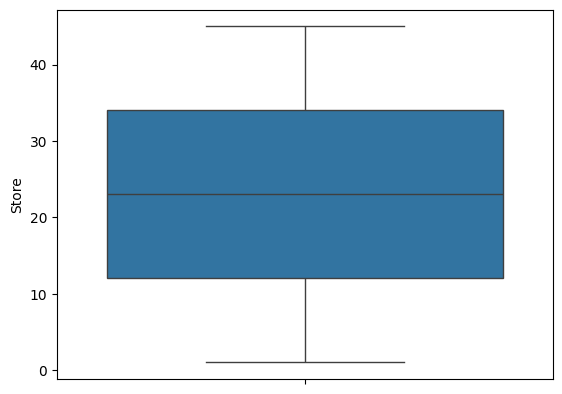

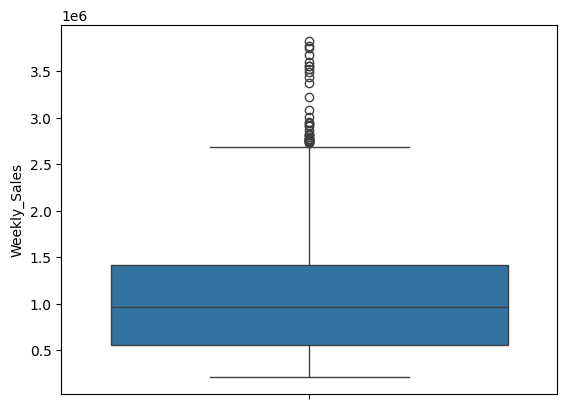

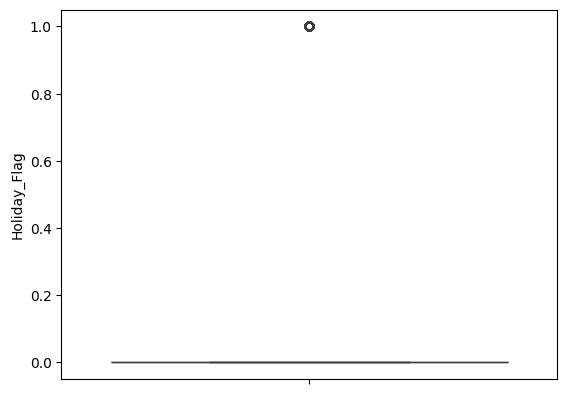

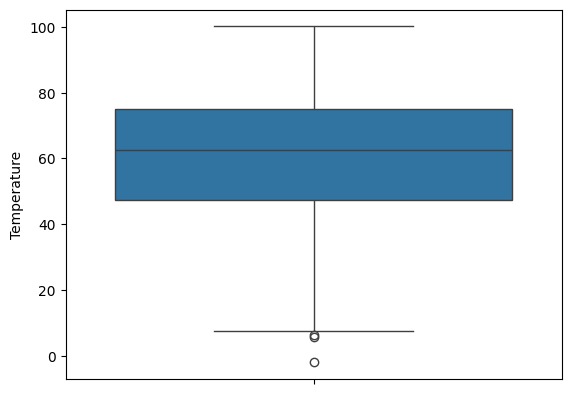

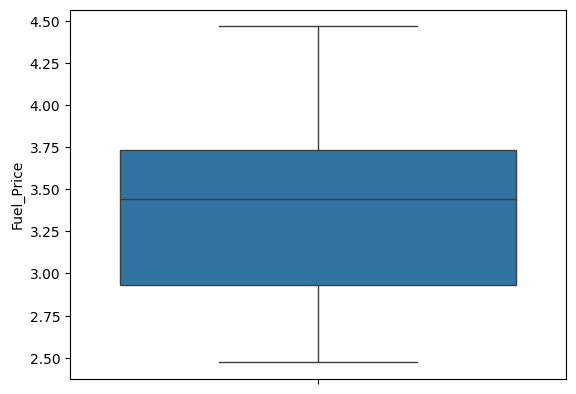

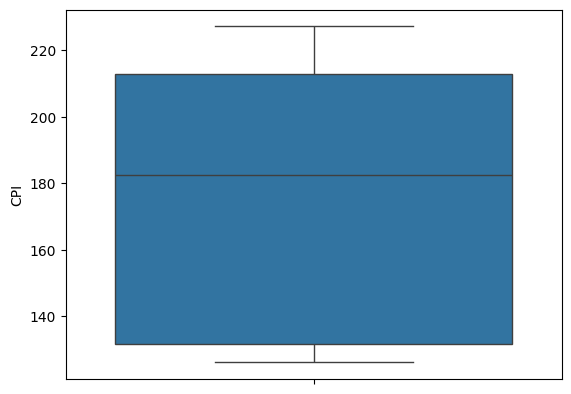

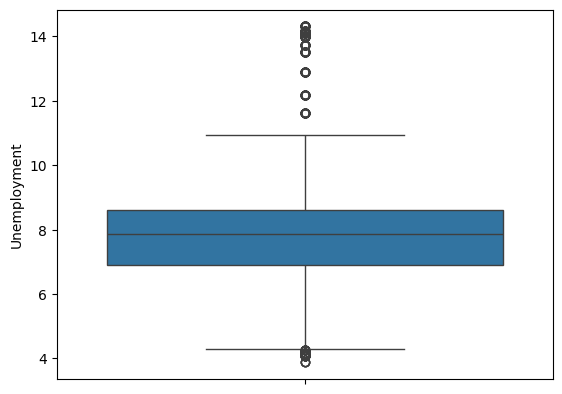

In [34]:
col = df.columns
for i in col:
    if i!= "Date" :
        sns.boxplot(y=df[i])
        plt.show()

In [35]:
df['Sales_clean'] = df['Weekly_Sales']
for s in df['Store'].unique():
    q1,q3 = df.loc[df.Store==s,'Weekly_Sales'].quantile([0.25,0.75])
    iqr = q3-q1; low=q1-1.5*iqr; high=q3+1.5*iqr
    df.loc[df.Store==s,'Sales_clean'] = df.loc[df.Store==s,'Sales_clean'].clip(low,high)

In [36]:
res=[]
for s in df.Store.unique():
    sdata=df[df.Store==s]
    y=sdata['Sales_clean']; X=sm.add_constant(sdata[['Unemployment']])
    try:
        model=sm.OLS(y,X).fit()
        res.append([s,model.params['Unemployment'],model.pvalues['Unemployment']])
    except: pass
unemp_effect=pd.DataFrame(res,columns=['Store','coef','pval']).sort_values('coef')
print(unemp_effect.head())

    Store           coef          pval
40     41 -178930.724375  1.729204e-11
38     39 -124701.921365  3.998074e-13
16     17  -91325.304993  1.805392e-04
3       4  -63681.550117  7.117705e-11
19     20  -61850.943919  1.851566e-01


In [37]:
corr_temp, _ = pearsonr(df['Temperature'], df['Weekly_Sales'])
print("Correlation between Sales and Temperature:", corr_temp)

Correlation between Sales and Temperature: -0.06381001317946955


In [38]:
temp_corr=df.groupby('Store').apply(
    lambda d: pearsonr(d['Temperature'],d['Sales_clean'])[0])
print(temp_corr.head())

Store
1   -0.202601
2   -0.288280
3   -0.397650
4   -0.172768
5   -0.169986
dtype: float64


/tmp/ipykernel_811/2309791917.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  temp_corr=df.groupby('Store').apply(


In [39]:
cpi_corr=df.groupby('Store').apply(
    lambda d: pearsonr(d['CPI'],d['Sales_clean'])[0])
print(cpi_corr.head())

Store
1    0.299365
2   -0.053473
3    0.385079
4    0.532434
5    0.431109
dtype: float64


/tmp/ipykernel_811/1547517175.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cpi_corr=df.groupby('Store').apply(


In [40]:
stats=df.groupby('Store')['Sales_clean'].mean().sort_values(ascending=False)
print("Top stores:",stats.head())
print("Worst store:",stats.tail(1))
print("Diff:",stats.iloc[0]-stats.iloc[-1])

Top stores: Store
20    2.077385e+06
4     2.071988e+06
14    1.997727e+06
13    1.969076e+06
2     1.896677e+06
Name: Sales_clean, dtype: float64
Worst store: Store
33    259790.441294
Name: Sales_clean, dtype: float64
Diff: 1817594.4931818182


In [41]:
from sklearn.linear_model import LinearRegression

In [45]:
df['Week_num']=np.arange(len(df))
x=df[['Week_num']]
y=df['Weekly_Sales']

[]

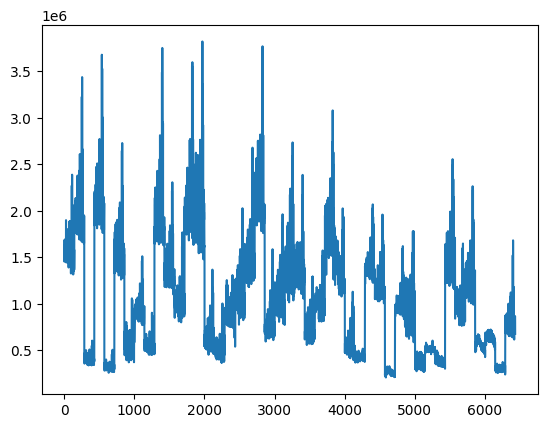

In [46]:
plt.plot(df['Week_num'],df['Weekly_Sales'])
plt.plot()

In [47]:
model=LinearRegression()

In [48]:
model.fit(x,y)

LinearRegression()

In [50]:
future_weeks = pd.DataFrame({'Week_num':np.arange(len(df),len(df)+12)})
future_sales= model.predict(future_weeks)

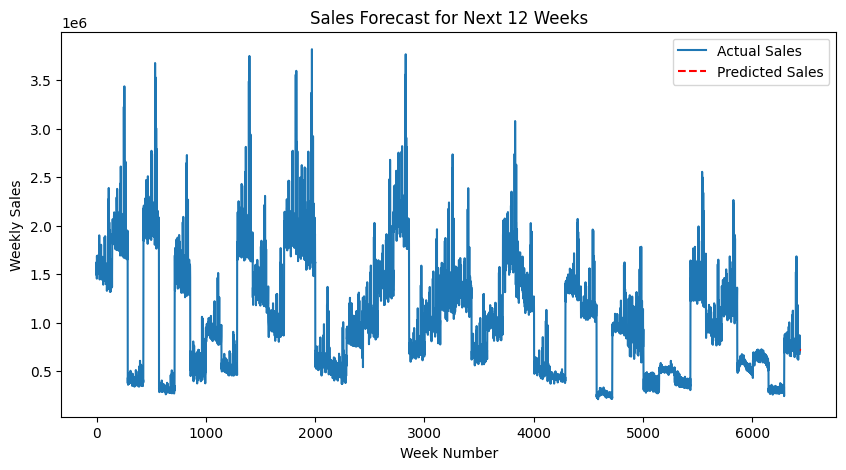

In [51]:
# Q2 - Plot forecast vs actual
plt.figure(figsize=(10,5))
plt.plot(df['Week_num'], df['Weekly_Sales'], label="Actual Sales")
plt.plot(future_weeks['Week_num'], future_sales, label="Predicted Sales", linestyle='dashed', color='red')
plt.title("Sales Forecast for Next 12 Weeks")
plt.xlabel("Week Number")
plt.ylabel("Weekly Sales")
plt.legend()
plt.show()